# SAM2UNet Kaggle Trainer with Augmentation + Distance Transform Auxiliary Training

Train SAM2UNet variants using **OpenEarthMap + Optional OSM road masks** with distance-transform auxiliary training and advanced augmentation.

**Features:**
- First run: baseline without OSM data
- Then sweep distance-transform auxiliary training with lambda 0.5 and max distances 3.0, 6.0, and 10.0
- Dual-output training: OEM (9-class) + OSM (binary roads) when OSM is enabled
- Combined loss: `Loss_total = Loss_OEM + lambda * Loss_OSM`
- Distance-transform weighting on the OSM loss for the auxiliary runs
- Flexible dataset: Falls back to OEM-only when OSM is disabled
- Seed-controlled random augmentations (HFlip, VFlip, Rotate90, Brightness/Contrast)
- Early stopping to prevent overfitting
- Memory-safe training (reduced batch size for large variant)
- Metrics: Precision, Recall, F1-Score, mIoU, Boundary IoU
- Learning curves and convergence plots for all runs
- Per-run training history export

## Configuration & Paths

In [1]:
import os
import sys
import json
import math
import shutil
import subprocess
from pathlib import Path
import torch
import numpy as np
import random

# ==============================================================================
# SEEDS
# ==============================================================================
SEEDS_TO_RUN = [42, 43, 44] 

# ==============================================================================
# User-configurable paths
# ==============================================================================
OPENEARTHMAP_DATASET_PATH = Path('/kaggle/input/datasets/tiagosantos71921/openearthmap-thesis/OpenEarthMap/OpenEarthMap_wo_xBD')
TRAIN_TXT_PATH = Path('/kaggle/input/datasets/tiagosantos71921/openearthmap-thesis/train.txt')
VAL_TXT_PATH = Path('/kaggle/input/datasets/tiagosantos71921/openearthmap-thesis/val.txt')
TEST_TXT_PATH = Path('/kaggle/input/datasets/tiagosantos71921/openearthmap-thesis/test.txt')

OSM_ROAD_DATASET_PATH = Path('/kaggle/input/datasets/tiagosantos71921/openstreetmap/OpenStreetMap/roads/binary_masks')

OSM_BLDG_DATASET_PATH = Path('/kaggle/input/datasets/tiagosantos71921/openstreetmap/OpenStreetMap/buildings/binary_masks')

SAM_CHECKPOINTS_DATASET_PATH = Path('/kaggle/input/datasets/tiagosantos71921/sam-checkpoints')

# ==============================================================================
# Training configuration
# ==============================================================================
MODEL_VARIANTS = ['tiny']
ROAD_CLASS_INDEX = 4
EPOCHS = 150
EVAL_EVERY = 1
IMAGE_SIZE = 512
NUM_CLASSES = 9
BATCH_SIZE_DEFAULT = 4
LR = 1e-3
WEIGHT_DECAY = 5e-4
NUM_WORKERS = 2
EARLY_STOP_PATIENCE = 10
EARLY_STOP_MIN_DELTA = 0.0001

KAGGLE = Path('/kaggle').exists()
WORK_DIR = Path('/kaggle/working/sam2unet_augmented_osm_run') if KAGGLE else Path('./sam2unet_augmented_osm_run')
OUTPUT_DIR = WORK_DIR / 'outputs'
HISTORY_DIR = WORK_DIR / 'history'

WORK_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
HISTORY_DIR.mkdir(parents=True, exist_ok=True)

torch.set_float32_matmul_precision('high')
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')

subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'hydra-core', 'omegaconf', 'iopath', 'fvcore', 'opencv-python-headless', 'albumentations'], check=True)

sam2_repo = WORK_DIR / 'sam2_repo'
if not sam2_repo.exists():
    subprocess.run(['git', 'clone', '--depth', '1', 'https://github.com/facebookresearch/sam2.git', str(sam2_repo)], check=True)
    try:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-e', str(sam2_repo)], check=True)
    except Exception:
        pass

sys.path.insert(0, str(sam2_repo))
from sam2.build_sam import build_sam2
print(f'\\nSAM2 repository ready at: {sam2_repo}')

Device: cuda
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 1.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 155.5/155.5 kB 4.9 MB/s eta 0:00:00


Cloning into '/kaggle/working/sam2unet_augmented_osm_run/sam2_repo'...


\nSAM2 repository ready at: /kaggle/working/sam2unet_augmented_osm_run/sam2_repo


## Configuration

In [2]:
import os
import sys
import json
import math
import shutil
import subprocess
from pathlib import Path
import torch
import numpy as np
import random
import matplotlib.pyplot as plt
import albumentations as A

# ==============================================================================
# SEEDS
# ==============================================================================
SEEDS_TO_RUN = [42] 
SEED = 42 # Default fallback

# ==============================================================================
# User-configurable paths
# ==============================================================================
OPENEARTHMAP_DATASET_PATH = Path('/kaggle/input/datasets/tiagosantos71921/openearthmap-thesis/OpenEarthMap/OpenEarthMap_wo_xBD')
TRAIN_TXT_PATH = Path('/kaggle/input/datasets/tiagosantos71921/openearthmap-thesis/train.txt')
VAL_TXT_PATH = Path('/kaggle/input/datasets/tiagosantos71921/openearthmap-thesis/val.txt')
TEST_TXT_PATH = Path('/kaggle/input/datasets/tiagosantos71921/openearthmap-thesis/test.txt')

OSM_DATASET_PATH = Path('/kaggle/input/datasets/tiagosantos71921/openstreetmap/OpenStreetMap/roads/binary_masks')
OSM_BLDG_DATASET_PATH = Path('/kaggle/input/datasets/tiagosantos71921/openstreetmap/OpenStreetMap/buildings/binary_masks')

SAM_CHECKPOINTS_DATASET_PATH = Path('/kaggle/input/datasets/tiagosantos71921/sam-checkpoints')

# ==============================================================================
# Training configuration
# ==============================================================================
MODEL_VARIANTS = ['tiny']
ROAD_CLASS_INDEX = 4
EPOCHS = 150
EVAL_EVERY = 1
IMAGE_SIZE = 512
NUM_CLASSES = 9
BATCH_SIZE_DEFAULT = 4
LR = 1e-3
WEIGHT_DECAY = 5e-4
NUM_WORKERS = 2
EARLY_STOP_PATIENCE = 5
EARLY_STOP_MIN_DELTA = 0.0001

KAGGLE = Path('/kaggle').exists()
WORK_DIR = Path('/kaggle/working/sam2unet_augmented_osm_run') if KAGGLE else Path('./sam2unet_augmented_osm_run')
OUTPUT_DIR = WORK_DIR / 'outputs'
HISTORY_DIR = WORK_DIR / 'history'

WORK_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
HISTORY_DIR.mkdir(parents=True, exist_ok=True)

# Global Initialization
np.random.seed(SEED)
random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True

torch.set_float32_matmul_precision('high')
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')

subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'hydra-core', 'omegaconf', 'iopath', 'fvcore', 'opencv-python-headless', 'albumentations'], check=True)

sam2_repo = WORK_DIR / 'sam2_repo'
if not sam2_repo.exists():
    subprocess.run(['git', 'clone', '--depth', '1', 'https://github.com/facebookresearch/sam2.git', str(sam2_repo)], check=True)
    try:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-e', str(sam2_repo)], check=True)
    except Exception:
        pass

sys.path.insert(0, str(sam2_repo))
from sam2.build_sam import build_sam2
print(f'\\nSAM2 repository ready at: {sam2_repo}')

Device: cuda
\nSAM2 repository ready at: /kaggle/working/sam2unet_augmented_osm_run/sam2_repo


## Dataset Utilities & Metrics

In [3]:
from glob import glob
import cv2
import torchvision.transforms.functional as TF
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.transforms import InterpolationMode
import numpy as np
import torch
import albumentations as A
from pathlib import Path

def get_augmentation_pipeline(seed=None):
    return A.Compose([
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.5),
        A.RandomRotate90(p=0.5),
        A.RandomBrightnessContrast(brightness_limit=0.05, contrast_limit=0.2, p=0.1),
    ], additional_targets={'osm': 'mask', 'osm_bldg': 'mask'})

def _is_openearthmap_root(path: Path) -> bool:
    if path is None or not path.exists() or not path.is_dir(): return False
    return all(x.exists() for x in [TRAIN_TXT_PATH, VAL_TXT_PATH, TEST_TXT_PATH])

def _find_openearthmap_root(explicit_path: Path):
    candidates = [explicit_path, Path('/kaggle/input/openearthmap-wo-xbd/OpenEarthMap_wo_xBD'), Path('../Datasets/OpenEarthMap_wo_xBD')]
    for c in candidates:
        if c is not None and _is_openearthmap_root(c): return c
    return None

def _read_split_file(root_dir: Path, split: str):
    split_file = TRAIN_TXT_PATH if split == 'train' else VAL_TXT_PATH if split == 'val' else TEST_TXT_PATH
    with open(split_file, 'r', encoding='utf-8') as f:
        return [line.strip() for line in f if line.strip()]

def _resolve_sample_paths(root_dir: Path, tile_name: str):
    tile_name = tile_name.strip()
    if not tile_name: return None, None
    filename = tile_name if Path(tile_name).suffix else f'{tile_name}.tif'
    stem = Path(filename).stem
    city = stem.rsplit('_', 1)[0] if '_' in stem else ''
    img_path = root_dir / city / 'images' / filename if city else root_dir / 'images' / filename
    lbl_path = root_dir / city / 'labels' / filename if city else root_dir / 'labels' / filename
    if img_path.exists() and lbl_path.exists(): return img_path, lbl_path
    return None, None

class ToTensor:
    def __call__(self, sample):
        image, label = sample['image'], sample['label']
        osm, osm_bldg = sample.get('osm', None), sample.get('osm_bldg', None)
        image = TF.to_tensor(image)
        label_np = np.array(label, dtype=np.uint8)
        if label_np.ndim == 3: label_np = label_np[:, :, 0]
        
        result = {'image': image, 'label': torch.from_numpy(label_np).long()}
        
        # Missing masks are safely filled with 255
        if osm is not None:
            osm_np = np.array(osm, dtype=np.uint8)
            result['osm'] = torch.from_numpy((osm_np > 127).astype(np.uint8)).long()
        else:
            result['osm'] = torch.full_like(result['label'], 255).long()
            
        if osm_bldg is not None:
            bldg_np = np.array(osm_bldg, dtype=np.uint8)
            result['osm_bldg'] = torch.from_numpy((bldg_np > 127).astype(np.uint8)).long()
        else:
            result['osm_bldg'] = torch.full_like(result['label'], 255).long()
            
        return result

class Resize:
    def __init__(self, size): self.size = (size, size)
    def __call__(self, sample):
        image, label = sample['image'], sample['label']
        osm, osm_bldg = sample.get('osm', None), sample.get('osm_bldg', None)
        result = {
            'image': TF.resize(image, self.size, InterpolationMode.BILINEAR),
            'label': TF.resize(label, self.size, InterpolationMode.NEAREST)
        }
        if osm is not None: result['osm'] = TF.resize(osm, self.size, InterpolationMode.NEAREST)
        if osm_bldg is not None: result['osm_bldg'] = TF.resize(osm_bldg, self.size, InterpolationMode.NEAREST)
        return result

class Normalize:
    def __init__(self, mean, std): self.mean, self.std = mean, std
    def __call__(self, sample):
        image, label = sample['image'], sample['label']
        result = {'image': TF.normalize(image, self.mean, self.std), 'label': label}
        if 'osm' in sample: result['osm'] = sample['osm']
        if 'osm_bldg' in sample: result['osm_bldg'] = sample['osm_bldg']
        return result

class AlbumentationsTransform:
    def __init__(self, augmentation_pipeline): self.aug = augmentation_pipeline
    def __call__(self, sample):
        image_np = np.array(sample['image'], dtype=np.uint8)
        label_np = np.array(sample['label'], dtype=np.uint8)
        osm_np = np.array(sample.get('osm', Image.new('L', sample['label'].size)), dtype=np.uint8)
        bldg_np = np.array(sample.get('osm_bldg', Image.new('L', sample['label'].size)), dtype=np.uint8)
        
        augmented = self.aug(image=image_np, mask=label_np, osm=osm_np, osm_bldg=bldg_np)
        res = {
            'image': Image.fromarray(augmented['image']),
            'label': Image.fromarray(augmented['mask']),
        }
        if 'osm' in sample: res['osm'] = Image.fromarray(augmented['osm'])
        if 'osm_bldg' in sample: res['osm_bldg'] = Image.fromarray(augmented['osm_bldg'])
        return res

GLOBAL_OSM_INDEX = None
GLOBAL_BLDG_INDEX = None

def _get_osm_index(osm_dir, is_bldg=False):
    global GLOBAL_OSM_INDEX, GLOBAL_BLDG_INDEX
    if is_bldg and GLOBAL_BLDG_INDEX is not None: return GLOBAL_BLDG_INDEX
    if not is_bldg and GLOBAL_OSM_INDEX is not None: return GLOBAL_OSM_INDEX
    
    index = {}
    if osm_dir and osm_dir.exists():
        for p in osm_dir.rglob('*'):
            if p.is_file():
                index[p.stem] = p
                index[p.parent.name] = p
                if p.stem.endswith('_highway_mask'):
                    index[p.stem.replace('_highway_mask', '')] = p
                if p.stem.endswith('_building_mask'):
                    index[p.stem.replace('_building_mask', '')] = p
    
    if is_bldg: GLOBAL_BLDG_INDEX = index
    else: GLOBAL_OSM_INDEX = index
    return index

class OpenEarthMapDataset(Dataset):
    def __init__(self, root_dir, osm_dir=None, bldg_dir=None, split='train', size=512, mode='train', seed=None):
        self.root_dir = Path(root_dir)
        self.osm_dir = Path(osm_dir) if osm_dir else None
        self.bldg_dir = Path(bldg_dir) if bldg_dir else None
        self.images, self.gts, self.osm_masks, self.bldg_masks = [], [], [], []
        
        osm_index = _get_osm_index(self.osm_dir, is_bldg=False)
        bldg_index = _get_osm_index(self.bldg_dir, is_bldg=True)
        
        for tile_name in _read_split_file(self.root_dir, split):
            image_path, label_path = _resolve_sample_paths(self.root_dir, tile_name)
            if image_path is not None:
                self.images.append(str(image_path))
                self.gts.append(str(label_path))
                
                stem = Path(tile_name if Path(tile_name).suffix else f'{tile_name}.tif').stem
                self.osm_masks.append(str(osm_index[stem]) if stem in osm_index else None)
                self.bldg_masks.append(str(bldg_index[stem]) if stem in bldg_index else None)
                
        pipeline = [Resize(size), ToTensor(), Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])]
        if mode == 'train': pipeline.insert(1, AlbumentationsTransform(get_augmentation_pipeline(seed=seed)))
        self.transform = transforms.Compose(pipeline)
        
    def __getitem__(self, idx):
        sample = {'image': Image.open(self.images[idx]).convert('RGB'), 'label': Image.open(self.gts[idx]).convert('L')}
        if self.osm_masks[idx] is not None: sample['osm'] = Image.open(self.osm_masks[idx]).convert('L')
        if self.bldg_masks[idx] is not None: sample['osm_bldg'] = Image.open(self.bldg_masks[idx]).convert('L')
        return self.transform(sample)
        
    def __len__(self): return len(self.images)

def _safe_div(num, den): return np.divide(num, den, out=np.zeros_like(num, dtype=np.float64), where=den > 0)

def _confusion_update(conf_mat, pred, target, num_classes=9, ignore_index=255):
    valid = target != ignore_index
    if not np.any(valid): return
    encoded = target[valid].astype(np.int64) * num_classes + pred[valid].astype(np.int64)
    conf_mat += np.bincount(encoded, minlength=num_classes**2).reshape(num_classes, num_classes)

def _mask_to_boundary(mask, dilation_ratio=0.02):
    h, w = mask.shape
    dilation = max(1, int(round(dilation_ratio * np.sqrt(h*h + w*w))))
    padded = cv2.copyMakeBorder(mask, 1, 1, 1, 1, cv2.BORDER_CONSTANT, value=0)
    eroded = cv2.erode(padded, np.ones((3, 3), dtype=np.uint8), iterations=dilation)[1:h+1, 1:w+1]
    return (mask - eroded).astype(np.uint8)

def _boundary_update(boundary_inter, boundary_union, pred, target, num_classes=9, ignore_index=255):
    valid = target != ignore_index
    if not np.any(valid): return
    pred, target = pred.copy(), target.copy()
    pred[~valid], target[~valid] = 0, 0
    for cls in range(num_classes):
        gt_bin = ((target == cls) & valid).astype(np.uint8)
        pred_bin = ((pred == cls) & valid).astype(np.uint8)
        if gt_bin.sum() == 0 and pred_bin.sum() == 0: continue
        gt_b, pred_b = _mask_to_boundary(gt_bin), _mask_to_boundary(pred_bin)
        boundary_inter[cls] += np.logical_and(gt_b, pred_b).sum()
        boundary_union[cls] += np.logical_or(gt_b, pred_b).sum()

def _scores_from_stats(conf_mat, boundary_inter, boundary_union):
    tp = np.diag(conf_mat)
    fp = conf_mat.sum(axis=0) - tp
    fn = conf_mat.sum(axis=1) - tp
    iou_per_class = _safe_div(tp, tp + fp + fn)
    precision = _safe_div(tp, tp + fp)
    recall = _safe_div(tp, tp + fn)
    f1_per_class = _safe_div(2 * precision * recall, precision + recall)
    biou_per_class = _safe_div(boundary_inter, boundary_union)
    return {
        'miou': float(np.nanmean(iou_per_class)),
        'precision': float(np.nanmean(precision)),
        'recall': float(np.nanmean(recall)),
        'f1': float(np.nanmean(f1_per_class)),
        'bmiou': float(np.nanmean(biou_per_class)),
        'road_iou': float(iou_per_class[ROAD_CLASS_INDEX]) if len(iou_per_class) > ROAD_CLASS_INDEX else 0.0,
        'per_class_iou': iou_per_class.tolist()
    }

@torch.no_grad()
def evaluate_model(model, dataloader, device, num_classes=9, ignore_index=255, is_dual=False):
    model.eval()
    conf_mat = np.zeros((num_classes, num_classes), dtype=np.float64)
    b_inter = np.zeros(num_classes, dtype=np.float64)
    b_union = np.zeros(num_classes, dtype=np.float64)
    for batch in dataloader:
        images = batch['image'].to(device, non_blocking=True)
        labels = batch['label'].long().cpu().numpy()
        logits_oem = model(images)[0] if is_dual else model(images)
        preds = torch.argmax(logits_oem, dim=1).cpu().numpy()
        for p, t in zip(preds, labels):
            _confusion_update(conf_mat, p, t, num_classes, ignore_index)
            _boundary_update(b_inter, b_union, p, t, num_classes, ignore_index)
    return _scores_from_stats(conf_mat, b_inter, b_union)

DATA_ROOT = _find_openearthmap_root(OPENEARTHMAP_DATASET_PATH)
if DATA_ROOT is None: raise FileNotFoundError('Could not find OpenEarthMap dataset root.')

## Model Architecture

In [4]:
import torch.nn as nn
import torch.nn.functional as F

VARIANT_CFG = {
    'tiny': 'sam2_hiera_t.yaml',
    'small': 'sam2_hiera_s.yaml',
    'base': 'sam2_hiera_b+.yaml',
    'large': 'sam2_hiera_l.yaml',
}

def _build_encoder_with_fallback(cfg_name, checkpoint_path):
    candidates = [cfg_name, f'sam2_configs/{cfg_name}', f'configs/sam2/{cfg_name}', f'configs/{cfg_name}']
    for c in candidates:
        try: return build_sam2(c, checkpoint_path)
        except Exception: pass
    raise RuntimeError(f'Failed to build SAM2 with config {cfg_name}.')

class DoubleConv(nn.Sequential):
    def __init__(self, in_channels, out_channels):
        super().__init__(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False), nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False), nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True)
        )

class Up(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.up = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
        self.conv = DoubleConv(in_channels, out_channels)
    def forward(self, x1, x2):
        x1 = self.up(x1)
        diff_y, diff_x = x2.size()[2] - x1.size()[2], x2.size()[3] - x1.size()[3]
        x1 = F.pad(x1, [diff_x // 2, diff_x - diff_x // 2, diff_y // 2, diff_y - diff_y // 2])
        return self.conv(torch.cat([x2, x1], dim=1))

class Adapter(nn.Module):
    def __init__(self, blk):
        super().__init__()
        self.block = blk
        dim = blk.attn.qkv.in_features
        self.prompt = nn.Sequential(nn.Linear(dim, 32), nn.GELU(), nn.Linear(32, dim), nn.GELU())
    def forward(self, x): return self.block(x + self.prompt(x))

class BasicConv2d(nn.Module):
    def __init__(self, in_planes, out_planes, kernel_size, stride=1, padding=0, dilation=1):
        super(BasicConv2d, self).__init__()
        self.conv = nn.Conv2d(in_planes, out_planes, kernel_size=kernel_size, stride=stride, padding=padding, dilation=dilation, bias=False)
        self.bn = nn.BatchNorm2d(out_planes)
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        x = self.conv(x)
        x = self.bn(x)
        return x

class RFBModified(nn.Module):
    def __init__(self, in_channel, out_channel):
        super(RFBModified, self).__init__()
        self.relu = nn.ReLU(True)
        self.branch0 = nn.Sequential(BasicConv2d(in_channel, out_channel, 1))
        self.branch1 = nn.Sequential(
            BasicConv2d(in_channel, out_channel, 1),
            BasicConv2d(out_channel, out_channel, kernel_size=(1, 3), padding=(0, 1)),
            BasicConv2d(out_channel, out_channel, kernel_size=(3, 1), padding=(1, 0)),
            BasicConv2d(out_channel, out_channel, 3, padding=3, dilation=3)
        )
        self.branch2 = nn.Sequential(
            BasicConv2d(in_channel, out_channel, 1),
            BasicConv2d(out_channel, out_channel, kernel_size=(1, 5), padding=(0, 2)),
            BasicConv2d(out_channel, out_channel, kernel_size=(5, 1), padding=(2, 0)),
            BasicConv2d(out_channel, out_channel, 3, padding=5, dilation=5)
        )
        self.branch3 = nn.Sequential(
            BasicConv2d(in_channel, out_channel, 1),
            BasicConv2d(out_channel, out_channel, kernel_size=(1, 7), padding=(0, 3)),
            BasicConv2d(out_channel, out_channel, kernel_size=(7, 1), padding=(3, 0)),
            BasicConv2d(out_channel, out_channel, 3, padding=7, dilation=7)
        )
        self.conv_cat = BasicConv2d(4*out_channel, out_channel, 3, padding=1)
        self.conv_res = BasicConv2d(in_channel, out_channel, 1)

    def forward(self, x):
        x0 = self.branch0(x)
        x1 = self.branch1(x)
        x2 = self.branch2(x)
        x3 = self.branch3(x)
        x_cat = self.conv_cat(torch.cat((x0, x1, x2, x3), 1))
        return self.relu(x_cat + self.conv_res(x))

class DualDecoder_SAM2UNet(nn.Module):
    def __init__(self, checkpoint_path=None, variant='tiny', num_classes=9):
        super().__init__()
        self.encoder = _build_encoder_with_fallback(VARIANT_CFG[variant], checkpoint_path)
        
        backbone_channels = self._infer_backbone_channels()
        for param in self.encoder.parameters(): param.requires_grad = False
        if hasattr(self.encoder, 'sam_mask_decoder'):
            for param in self.encoder.sam_mask_decoder.parameters(): param.requires_grad = True
            
        self.rfb1 = RFBModified(backbone_channels[0], 64)
        self.rfb2 = RFBModified(backbone_channels[1], 64)
        self.rfb3 = RFBModified(backbone_channels[2], 64)
        
        self.up1 = Up(128, 64)
        self.up2 = Up(128, 64)
        
        self.side1 = nn.Conv2d(64, num_classes, kernel_size=1)
        self.side2 = nn.Conv2d(64, num_classes, kernel_size=1)
        self.head = nn.Conv2d(64, num_classes, kernel_size=1)
        
        self.osm_side1 = nn.Conv2d(64, 3, kernel_size=1)
        self.osm_side2 = nn.Conv2d(64, 3, kernel_size=1)
        self.osm_head = nn.Conv2d(64, 3, kernel_size=1)
        
        self.upsample8 = nn.Upsample(scale_factor=8, mode='bilinear', align_corners=True)
        self.upsample4 = nn.Upsample(scale_factor=4, mode='bilinear', align_corners=True)
        
        blocks = []
        for block in self.encoder.image_encoder.trunk.blocks: blocks.append(Adapter(block))
        self.encoder.image_encoder.trunk.blocks = nn.Sequential(*blocks)

    @torch.no_grad()
    def _infer_backbone_channels(self):
        was_training = self.encoder.training
        self.encoder.eval()
        first_param = next(self.encoder.parameters())
        probe = torch.zeros(1, 3, IMAGE_SIZE, IMAGE_SIZE, device=first_param.device)
        feats = self.encoder.forward_image(probe)['backbone_fpn']
        if was_training: self.encoder.train()
        return [f.shape[1] for f in feats]

    def forward(self, x):
        feats = self.encoder.forward_image(x)['backbone_fpn']
        # This is the line that was cut off! It is fully restored here.
        x1, x2, x3 = self.rfb1(feats[0]), self.rfb2(feats[1]), self.rfb3(feats[2])
        
        x = self.up1(x3, x2)
        out2_oem, out2_osm = self.side1(x), self.osm_side1(x)
        
        x = self.up2(x, x1)
        out3_oem, out3_osm = self.side2(x), self.osm_side2(x)
        
        out_oem = self.upsample4(self.head(x)) + self.upsample8(out2_oem) + self.upsample4(out3_oem)
        out_osm = self.upsample4(self.osm_head(x)) + self.upsample8(out2_osm) + self.upsample4(out3_osm)
        
        return out_oem, out_osm

print('Model definition ready.')

Model definition ready.


## Training Loop

In [5]:
from torch.amp import autocast, GradScaler
import json
import torch
import torch.nn as nn
import numpy as np
import cv2
from pathlib import Path
from torch.utils.data import DataLoader
import random

class EarlyStopping:
    def __init__(self, patience=10, min_delta=0.0001, metric_name='miou'):
        self.patience = patience
        self.min_delta = min_delta
        self.metric_name = metric_name
        self.counter = 0
        self.best_metric = None
        self.best_epoch = None

    def __call__(self, current_metric, epoch):
        if self.best_metric is None or current_metric > self.best_metric + self.min_delta:
            self.best_metric = current_metric
            self.best_epoch = epoch
            self.counter = 0
            return False
        self.counter += 1
        return self.counter >= self.patience

def _find_checkpoint_root(explicit_path: Path):
    candidates = [explicit_path, Path('/kaggle/input/sam2-checkpoints'), Path('/kaggle/input/sam2-checkpoints/checkpoints')]
    for c in candidates:
        if c is not None and c.exists() and c.is_dir(): return c
    return None

def _find_ckpt(root: Path, pattern):
    direct = root / pattern
    if direct.exists(): return direct
    nested = list(root.rglob(pattern))
    return nested[0] if nested else None

def _distance_transform_weights(mask, max_distance):
    if isinstance(mask, torch.Tensor):
        mask_np = mask.detach().cpu().numpy()
    else:
        mask_np = np.asarray(mask)
    valid = mask_np != 255
    if not np.any(valid):
        return np.ones_like(mask_np, dtype=np.float32)
    binary = (mask_np > 0).astype(np.uint8)
    dist = cv2.distanceTransform(1 - binary, cv2.DIST_L2, 5)
    max_distance = float(max_distance)
    weights = np.where(dist <= max_distance, (max_distance - dist) / max(max_distance, 1e-6), 0.0)
    weights[~valid] = 0.0
    return weights.astype(np.float32)

CKPT_PATTERNS = {'tiny': 'sam2_hiera_tiny.pt'}
ckpt_root = _find_checkpoint_root(SAM_CHECKPOINTS_DATASET_PATH)
variant_ckpts = {v: _find_ckpt(ckpt_root, CKPT_PATTERNS[v]) for v in MODEL_VARIANTS}

history_all = {}

run_plan = [
    {'name': 'baseline', 'label': 'Baseline (OEM Only)', 'lambda_osm': 0.0, 'lambda_bldg': 0.0, 'use_osm_data': False, 'use_bldg_data': False, 'dt_max_distance': 6.0},
    {'name': 'roads_only_L0p5', 'label': 'Roads Only (L=0.5)', 'lambda_osm': 0.5, 'lambda_bldg': 0.0, 'use_osm_data': True, 'use_bldg_data': False, 'dt_max_distance': 6.0},
    {'name': 'roads_bldg_L0p25', 'label': 'Roads+Bldg (L_bldg=0.25)', 'lambda_osm': 0.5, 'lambda_bldg': 0.25, 'use_osm_data': True, 'use_bldg_data': True, 'dt_max_distance': 6.0},
    {'name': 'roads_bldg_L0p5', 'label': 'Roads+Bldg (L_bldg=0.5)', 'lambda_osm': 0.5, 'lambda_bldg': 0.5, 'use_osm_data': True, 'use_bldg_data': True, 'dt_max_distance': 6.0},
    {'name': 'roads_bldg_L0p75', 'label': 'Roads+Bldg (L_bldg=0.75)', 'lambda_osm': 0.5, 'lambda_bldg': 0.75, 'use_osm_data': True, 'use_bldg_data': True, 'dt_max_distance': 6.0},
]

for SEED in SEEDS_TO_RUN:
    print('\n' + '=' * 100)
    print(f'STARTING SEED: {SEED}')
    print('=' * 100)
    
    np.random.seed(SEED)
    random.seed(SEED)
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(SEED)
        torch.cuda.manual_seed_all(SEED)

    for run in run_plan:
        variant = 'tiny'
        run_name = f"{run['name']}_seed{SEED}"
        
        run_osm_dir = OSM_DATASET_PATH if run['use_osm_data'] else None
        run_bldg_dir = OSM_BLDG_DATASET_PATH if run['use_bldg_data'] else None
        
        train_dataset = OpenEarthMapDataset(DATA_ROOT, osm_dir=run_osm_dir, bldg_dir=run_bldg_dir, split='train', size=IMAGE_SIZE, mode='train', seed=SEED)
        val_dataset = OpenEarthMapDataset(DATA_ROOT, osm_dir=run_osm_dir, bldg_dir=run_bldg_dir, split='val', size=IMAGE_SIZE, mode='val', seed=SEED)
        test_dataset = OpenEarthMapDataset(DATA_ROOT, osm_dir=run_osm_dir, bldg_dir=run_bldg_dir, split='test', size=IMAGE_SIZE, mode='val', seed=SEED)

        train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE_DEFAULT, shuffle=True, num_workers=NUM_WORKERS, pin_memory=True)
        val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE_DEFAULT, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
        test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE_DEFAULT, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

        print(f"\nTraining run: {run_name} | {run['label']}")
        
        model = DualDecoder_SAM2UNet(checkpoint_path=str(variant_ckpts[variant]), variant=variant, num_classes=NUM_CLASSES).to(device)

        criterion_oem = torch.nn.CrossEntropyLoss(ignore_index=255)
        criterion_osm = torch.nn.MSELoss()
        
        optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, EPOCHS, eta_min=1e-7)
        scaler = GradScaler('cuda')
        early_stopper = EarlyStopping(patience=EARLY_STOP_PATIENCE, min_delta=EARLY_STOP_MIN_DELTA, metric_name='miou')

        run_dir = OUTPUT_DIR / run_name
        run_dir.mkdir(parents=True, exist_ok=True)

        history = []
        actual_epochs = 0
        run_best_model_state = None
        run_best_metrics = None

        for epoch in range(1, EPOCHS + 1):
            model.train()
            running_loss = 0.0

            for step, batch in enumerate(train_loader):
                images = batch['image'].to(device, non_blocking=True)
                masks_oem = batch['label'].to(device, non_blocking=True)

                optimizer.zero_grad(set_to_none=True)
                with autocast('cuda'):
                    logits_oem, logits_osm = model(images)
                    loss = criterion_oem(logits_oem, masks_oem)
                    
                    if run['use_osm_data'] and 'osm' in batch:
                        masks_osm = batch['osm'].to(device, non_blocking=True)
                        road_probs = torch.sigmoid(logits_osm[:, 1:2])
                        dt_targets = torch.from_numpy(
                            np.stack([_distance_transform_weights(mask, run['dt_max_distance']) for mask in masks_osm.detach().cpu().numpy()])
                        ).to(device=device, dtype=road_probs.dtype).unsqueeze(1)
                        loss = loss + (run['lambda_osm'] * criterion_osm(road_probs, dt_targets))
                        
                    if run['use_bldg_data'] and 'osm_bldg' in batch:
                        masks_bldg = batch['osm_bldg'].to(device, non_blocking=True)
                        bldg_probs = torch.sigmoid(logits_osm[:, 2:3])
                        dt_targets_bldg = torch.from_numpy(
                            np.stack([_distance_transform_weights(mask, run['dt_max_distance']) for mask in masks_bldg.detach().cpu().numpy()])
                        ).to(device=device, dtype=bldg_probs.dtype).unsqueeze(1)
                        loss = loss + (run['lambda_bldg'] * criterion_osm(bldg_probs, dt_targets_bldg))

                scaler.scale(loss).backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(optimizer)
                scaler.update()

                running_loss += loss.item()
                if step % 100 == 0:
                    print(f'[{run_name}] Epoch [{epoch}/{EPOCHS}] Step [{step}/{len(train_loader)}] Loss: {loss.item():.4f}')

            scheduler.step()
            avg_loss = running_loss / max(len(train_loader), 1)

            do_eval = (epoch % EVAL_EVERY == 0) or (epoch == EPOCHS)
            metrics = None
            if do_eval:
                metrics = evaluate_model(model, val_loader, device, num_classes=NUM_CLASSES, ignore_index=255, is_dual=True)
                print(f"[{run_name}] Epoch [{epoch}/{EPOCHS}] mIoU={metrics['miou']:.4f} B-mIoU={metrics['bmiou']:.4f} RoadIoU={metrics['road_iou']:.4f}")

                if run_best_metrics is None or metrics['miou'] > run_best_metrics['miou']:
                    run_best_model_state = model.state_dict().copy()
                    run_best_metrics = metrics

                if early_stopper(metrics['miou'], epoch):
                    print(f'[{run_name}] Early stopping at epoch {epoch}. Best mIoU={early_stopper.best_metric:.4f}')
                    actual_epochs = epoch
                    break

            actual_epochs = epoch
            history.append({
                'epoch': epoch, 'miou': float(metrics['miou']) if metrics else None,
                'bmiou': float(metrics['bmiou']) if metrics else None, 'road_iou': float(metrics['road_iou']) if metrics else None,
            })

        # Save Metrics
        model.load_state_dict(run_best_model_state)
        test_metrics = evaluate_model(model, test_loader, device, num_classes=NUM_CLASSES, ignore_index=255, is_dual=True)

        metrics_out = {
            'test': test_metrics, 'best_epoch': early_stopper.best_epoch if early_stopper.best_epoch is not None else actual_epochs,
            'best_miou': early_stopper.best_metric, 'seed': SEED
        }

        with open(HISTORY_DIR / f'{run_name}_metrics.json', 'w', encoding='utf-8') as f:
            json.dump(metrics_out, f, indent=2)

        history_all[run_name] = {
            'name': run_name, 
            'label': run['label'], 
            'seed': SEED, 
            'history': history, 
            'final_metrics': metrics_out
        }
        
        # Save model immediately to prevent data loss!
        torch.save(run_best_model_state, run_dir / f'{run_name}_final.pth')
        print(f'[{run_name}] Final model safely saved to: {run_dir / f"{run_name}_final.pth"}')
        
        del model
        if torch.cuda.is_available(): torch.cuda.empty_cache()

print('\nTraining complete for all selected seeds.')


STARTING SEED: 42

Training run: baseline_seed42 | Baseline (OEM Only)
[baseline_seed42] Epoch [1/150] Step [0/470] Loss: 2.4900
[baseline_seed42] Epoch [1/150] Step [100/470] Loss: 1.3245
[baseline_seed42] Epoch [1/150] Step [200/470] Loss: 1.1550
[baseline_seed42] Epoch [1/150] Step [300/470] Loss: 0.9290
[baseline_seed42] Epoch [1/150] Step [400/470] Loss: 0.8928
[baseline_seed42] Epoch [1/150] mIoU=0.5007 B-mIoU=0.3907 RoadIoU=0.3580
[baseline_seed42] Epoch [2/150] Step [0/470] Loss: 1.0776
[baseline_seed42] Epoch [2/150] Step [100/470] Loss: 0.8231
[baseline_seed42] Epoch [2/150] Step [200/470] Loss: 0.6753
[baseline_seed42] Epoch [2/150] Step [300/470] Loss: 1.1695
[baseline_seed42] Epoch [2/150] Step [400/470] Loss: 1.2247
[baseline_seed42] Epoch [2/150] mIoU=0.5444 B-mIoU=0.4297 RoadIoU=0.3454
[baseline_seed42] Epoch [3/150] Step [0/470] Loss: 0.9510
[baseline_seed42] Epoch [3/150] Step [100/470] Loss: 0.7079
[baseline_seed42] Epoch [3/150] Step [200/470] Loss: 0.6772
[baselin

## Visualizations & Summary

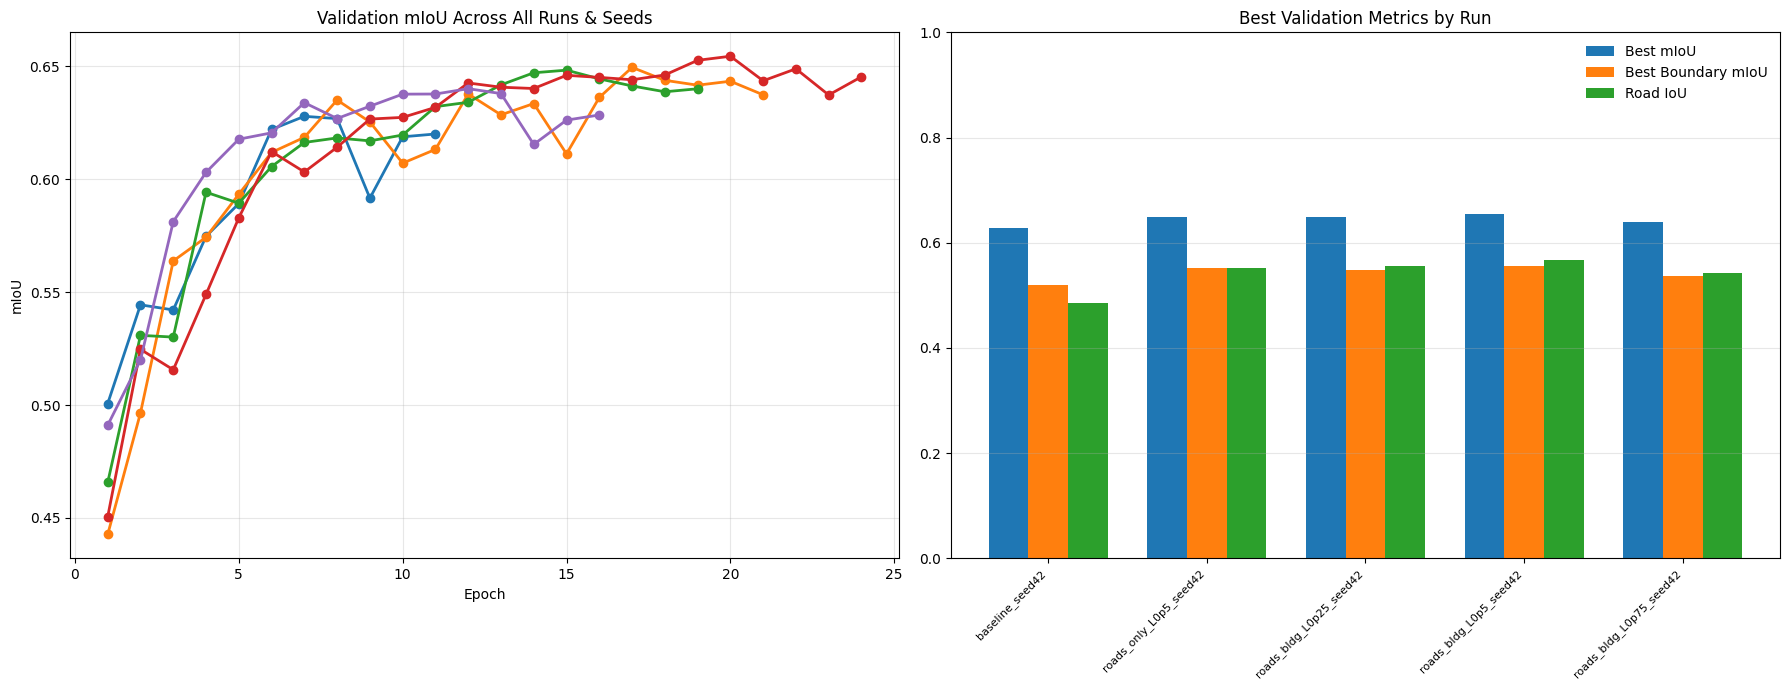

Saved summary plot to: /kaggle/working/sam2unet_augmented_osm_run/training_summary_all_runs.png

TRAINING SUMMARY ALL RUNS
Run                                          OSM       Lambda    DT Max    Best Epoch  Best mIoU   Best BIoU   Road IoU  
baseline_seed42                              No        N/A       6.0       7           0.6278      0.5202      0.4855    
roads_only_L0p5_seed42                       Yes       0.5       6.0       17          0.6495      0.5516      0.5514    
roads_bldg_L0p25_seed42                      Yes       0.5       6.0       15          0.6483      0.5485      0.5566    
roads_bldg_L0p5_seed42                       Yes       0.5       6.0       20          0.6544      0.5553      0.5664    
roads_bldg_L0p75_seed42                      Yes       0.5       6.0       12          0.6401      0.5364      0.5424    


In [6]:
import matplotlib.pyplot as plt
import numpy as np
import json

run_names = list(history_all.keys())
if not run_names:
    raise RuntimeError('No training runs were collected.')

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

for run_name in run_names:
    run_info = history_all[run_name]
    hist = run_info['history']
    epochs = [row['epoch'] for row in hist if row['miou'] is not None]
    miou_vals = [row['miou'] for row in hist if row['miou'] is not None]
    if not epochs:
        continue
    
    axes[0].plot(epochs, miou_vals, marker='o', linewidth=2, label=f"{run_info['label']} (Seed {run_info['seed']})")

axes[0].set_title('Validation mIoU Across All Runs & Seeds')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('mIoU')
axes[0].grid(True, alpha=0.3)

# axes[0].legend(loc='best', fontsize=9) 

summary_rows = []
for run_name in run_names:
    run_info = history_all[run_name]
    hist = run_info['history']
    final_metrics = run_info['final_metrics']
    
    valid_hist = [row for row in hist if row['miou'] is not None]
    best_row = max(valid_hist, key=lambda row: row['miou']) if valid_hist else None
    
    # Safely extract configuration details from the run_plan
    base_name = run_name.rsplit('_seed', 1)[0]
    config = next((item for item in run_plan if item["name"] == base_name), None)
    
    summary_rows.append({
        'name': run_name,
        'best_epoch': final_metrics.get('best_epoch', 'N/A'),
        'best_miou': final_metrics.get('best_miou', 'N/A'),
        'best_bmiou': best_row['bmiou'] if best_row is not None else np.nan,
        'road_iou': best_row['road_iou'] if best_row is not None else np.nan,
        'use_osm_data': config['use_osm_data'] if config else False,
        'lambda_osm': config['lambda_osm'] if config else 0.0,
        'dt_max_distance': config['dt_max_distance'] if config else None,
    })

x = np.arange(len(summary_rows))
width = 0.25
axes[1].bar(x - width, [row['best_miou'] for row in summary_rows], width, label='Best mIoU')
axes[1].bar(x, [row['best_bmiou'] for row in summary_rows], width, label='Best Boundary mIoU')
axes[1].bar(x + width, [row['road_iou'] for row in summary_rows], width, label='Road IoU')
axes[1].set_xticks(x)
# Increased rotation and decreased font size so the 15 seed labels fit nicely
axes[1].set_xticklabels([row['name'] for row in summary_rows], rotation=45, ha='right', fontsize=8) 
axes[1].set_ylim(0, 1.0)
axes[1].set_title('Best Validation Metrics by Run')
axes[1].grid(axis='y', alpha=0.3)
axes[1].legend(frameon=False)

plt.tight_layout()
plot_path = WORK_DIR / 'training_summary_all_runs.png'
plt.savefig(plot_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved summary plot to: {plot_path}')

print('\n' + '=' * 100)
print('TRAINING SUMMARY ALL RUNS')
print('=' * 100)
# Increased spacing to accommodate the "_seedXX" suffix
print(f"{'Run':<45}{'OSM':<10}{'Lambda':<10}{'DT Max':<10}{'Best Epoch':<12}{'Best mIoU':<12}{'Best BIoU':<12}{'Road IoU':<10}")
for row in summary_rows:
    osm_text = 'No' if not row['use_osm_data'] else 'Yes'
    lambda_text = 'N/A' if not row['use_osm_data'] else f"{row['lambda_osm']:.1f}"
    dt_text = 'N/A' if row['dt_max_distance'] is None else f"{row['dt_max_distance']:.1f}"
    print(f"{row['name']:<45}{osm_text:<10}{lambda_text:<10}{dt_text:<10}{str(row['best_epoch']):<12}{row['best_miou']:<12.4f}{row['best_bmiou']:<12.4f}{row['road_iou']:<10.4f}")

# Safely build the payload using the cleaned summary_rows
comparison_payload = {
    'runs': [
        {
            'name': row['name'],
            'use_osm_data': row['use_osm_data'],
            'dt_max_distance': row['dt_max_distance'],
            'best_epoch': row['best_epoch'],
            'best_miou': row['best_miou'],
            'best_bmiou': row['best_bmiou']
        }
        for row in summary_rows
    ]
}

with open(WORK_DIR / 'training_summary_all_runs.json', 'w', encoding='utf-8') as handle:
    json.dump(comparison_payload, handle, indent=2)

## Final Results and Metrics

In [7]:
import json
import numpy as np

print("==========================================================================================")
print("FINAL PAPER RESULTS (TEST SET): MEAN ± STD DEV")
print("==========================================================================================\n")

# Get unique run bases (without the _seedX suffix)
run_bases = []
for run in run_plan:
    run_bases.append(run['name'])

# Print Table Header
print(f"{'Configuration':<35} | {'Test mIoU':<18} | {'Test Boundary mIoU':<18} | {'Test Road IoU':<18}")
print("-" * 95)

for base in run_bases:
    mious, bmious, road_ious = [], [], []
    
    # Collect results for all seeds
    for seed in SEEDS_TO_RUN:
        run_name = f"{base}_seed{seed}"
        json_path = HISTORY_DIR / f"{run_name}_metrics.json"
        
        if json_path.exists():
            with open(json_path, 'r') as f:
                data = json.load(f)
                mious.append(data['test']['miou'])
                bmious.append(data['test']['bmiou'])
                road_ious.append(data['test']['road_iou'])
                
    if len(mious) > 0:
        # Calculate Mean and Std
        m_miou, std_miou = np.mean(mious), np.std(mious)
        m_bmiou, std_bmiou = np.mean(bmious), np.std(bmious)
        m_road, std_road = np.mean(road_ious), np.std(road_ious)
        
        # Get label from run_plan
        label = next(item for item in run_plan if item["name"] == base)["label"]
        
        # Format strings
        miou_str = f"{m_miou:.4f} ± {std_miou:.4f}"
        bmiou_str = f"{m_bmiou:.4f} ± {std_bmiou:.4f}"
        road_str = f"{m_road:.4f} ± {std_road:.4f}"
        
        print(f"{label:<35} | {miou_str:<18} | {bmiou_str:<18} | {road_str:<18}")

FINAL PAPER RESULTS (TEST SET): MEAN ± STD DEV

Configuration                       | Test mIoU          | Test Boundary mIoU | Test Road IoU     
-----------------------------------------------------------------------------------------------
Baseline (OEM Only)                 | 0.6300 ± 0.0000    | 0.5259 ± 0.0000    | 0.5427 ± 0.0000   
Roads Only (L=0.5)                  | 0.6322 ± 0.0000    | 0.5442 ± 0.0000    | 0.5535 ± 0.0000   
Roads+Bldg (L_bldg=0.25)            | 0.6414 ± 0.0000    | 0.5419 ± 0.0000    | 0.5278 ± 0.0000   
Roads+Bldg (L_bldg=0.5)             | 0.6326 ± 0.0000    | 0.5397 ± 0.0000    | 0.5605 ± 0.0000   
Roads+Bldg (L_bldg=0.75)            | 0.6293 ± 0.0000    | 0.5235 ± 0.0000    | 0.5334 ± 0.0000   
